# EDA Hubs – Método 1 (Basado en hubs_id.xlsx)
Análisis exploratorio de los hubs del método 1 y sus cargas.
- **Hubs**: `../utils/hubs_id.xlsx`
- **Cargas**: `parquetloadsfull.parquet` (con columnas `HubOrigin`, `HubDestination`)

In [1]:
import polars as pl
import pandas as pd
import numpy as np
import plotly.express as px
import folium
from folium.plugins import HeatMap
import ast
import warnings
warnings.filterwarnings('ignore')

region5 = {
    'AL': 'SOUTHEAST', 'AR': 'SOUTHEAST', 'GA': 'SOUTHEAST', 'MS': 'SOUTHEAST',
    'VA': 'SOUTHEAST', 'KY': 'SOUTHEAST', 'TN': 'SOUTHEAST', 'FL': 'SOUTHEAST',
    'SC': 'SOUTHEAST', 'NC': 'SOUTHEAST', 'WV': 'SOUTHEAST', 'LA': 'SOUTHEAST',
    'AZ': 'SOUTHWEST', 'NM': 'SOUTHWEST', 'TX': 'SOUTHWEST', 'OK': 'SOUTHWEST',
    'IL': 'MIDWEST', 'IA': 'MIDWEST', 'NE': 'MIDWEST', 'SD': 'MIDWEST',
    'MO': 'MIDWEST', 'IN': 'MIDWEST', 'MN': 'MIDWEST', 'MI': 'MIDWEST',
    'WI': 'MIDWEST', 'KS': 'MIDWEST', 'ND': 'MIDWEST', 'OH': 'MIDWEST',
    'UT': 'WEST', 'NV': 'WEST', 'ID': 'WEST', 'WY': 'WEST',
    'CO': 'WEST', 'MT': 'WEST', 'WA': 'WEST', 'OR': 'WEST', 'CA': 'WEST',
    'MD': 'NORTHEAST', 'ME': 'NORTHEAST', 'NH': 'NORTHEAST', 'VT': 'NORTHEAST',
    'MA': 'NORTHEAST', 'PA': 'NORTHEAST', 'NY': 'NORTHEAST', 'RI': 'NORTHEAST',
    'CT': 'NORTHEAST', 'NJ': 'NORTHEAST', 'DE': 'NORTHEAST'
}

In [2]:
import numpy as np

def haversine_vec(lat1, lon1, lat2, lon2):
    """Haversine vectorizado – acepta Series o arrays de numpy."""
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
    return 3958.8 * 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))

## 1. Cargar datos

In [3]:
import gc

COLS = [
    'ID', 'HubOrigin', 'HubDestination',
    'LatOrigin', 'LngOrigin', 'LatDestination', 'LngDestination',
    'StateOrigin', 'StateDestination',
    'RatePerMile', 'Distance', 'Posted'
]

_probe = pl.read_parquet('../2. cleaning_loads/parquetloadsfull.parquet', n_rows=1)
df = (
    pl.scan_parquet('../2. cleaning_loads/parquetloadsfull.parquet')
    .select([c for c in COLS if c in _probe.columns])
    .filter(
        pl.col('StateOrigin').is_in(list(region5.keys())) |
        pl.col('StateDestination').is_in(list(region5.keys()))
    )
    .collect()
    .to_pandas()
)

# float64 → float32 para columnas de coordenadas: ahorra ~50% RAM en esas cols
for col in ['LatOrigin', 'LngOrigin', 'LatDestination', 'LngDestination']:
    if col in df.columns:
        df[col] = df[col].astype('float32')

print(f'Total cargas: {df.shape[0]:,} | Memoria: {df.memory_usage(deep=True).sum()/1e6:.0f} MB')

Total cargas: 57,573,424 | Memoria: 7189 MB


## 2. Distribución de cargas por hub origen

In [4]:
hubs = pd.read_excel('../utils/hubs_id.xlsx')
hubs = hubs.dropna(subset=['lat', 'lng']).reset_index(drop=True)
print(f'Hubs M1: {len(hubs)}')

Hubs M1: 194


In [5]:
cargas_por_hub = (
    df.groupby('HubOrigin')['ID']
    .count()
    .reset_index()
    .rename(columns={'ID': 'cargas_origen', 'HubOrigin': 'new_name'})
    .sort_values('cargas_origen', ascending=False)
)

cargas_dest = (
    df.groupby('HubDestination')['ID']
    .count()
    .reset_index()
    .rename(columns={'ID': 'cargas_dest', 'HubDestination': 'new_name'})
)

hub_stats = (
    hubs.merge(cargas_por_hub, on='new_name', how='left')
        .merge(cargas_dest, on='new_name', how='left')
)
hub_stats['cargas_origen'] = hub_stats['cargas_origen'].fillna(0).astype(int)
hub_stats['cargas_dest']   = hub_stats['cargas_dest'].fillna(0).astype(int)
hub_stats['total_cargas']  = hub_stats['cargas_origen'] + hub_stats['cargas_dest']
hub_stats['inbound_ratio'] = hub_stats['cargas_dest'] / (hub_stats['total_cargas'] + 1e-9)
hub_stats.head(10)

,id,old_name,lat,lng,new_name,state,state_name,region,cargas_origen,cargas_dest,total_cargas,inbound_ratio
0,1,Demopolis (AL),32.8785,-87.7429,Demopolis (AL),AL,Alabama,SOUTHEAST,343923,86448,430371,0.200869
1,2,Opelika (AL),32.9229,-85.9358,Auburn (AL),AL,Alabama,SOUTHEAST,189869,178498,368367,0.484566
2,3,Troy (AL),31.7182,-85.8178,Troy (AL),AL,Alabama,SOUTHEAST,305112,104309,409421,0.254772
3,4,Muscle Shoals (AL),34.2331,-87.6175,Muscle Shoals (AL),AL,Alabama,SOUTHEAST,321551,230456,552007,0.417487
4,5,Thomasville (AL),31.4058,-87.8442,Thomasville (AL),AL,Alabama,SOUTHEAST,550916,207589,758505,0.273682
5,6,Birmingham (AL),33.7643,-86.4742,Birmingham (AL),AL,Alabama,SOUTHEAST,536042,421678,957720,0.440294
6,7,Lake Havasu City (AZ),33.8984,-113.9962,Quartzsite (AZ),AZ,Arizona,SOUTHWEST,112052,70476,182528,0.386111
7,8,Flagstaff (AZ),34.7195,-112.0016,Cottonwood (AZ),AZ,Arizona,SOUTHWEST,24690,48817,73507,0.664114
8,9,Phoenix (AZ),33.5024,-112.3588,Glendale (AZ),AZ,Arizona,SOUTHWEST,384231,526140,910371,0.577940
9,10,Morenci (AZ),33.0539,-109.3310,Morenci (AZ),AZ,Arizona,SOUTHWEST,15714,17757,33471,0.530519


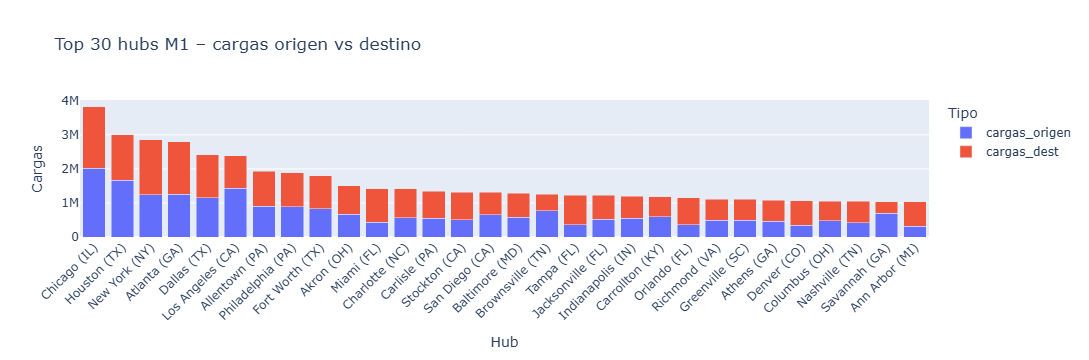

In [6]:
fig = px.bar(
    hub_stats.sort_values('total_cargas', ascending=False).head(30),
    x='new_name', y=['cargas_origen', 'cargas_dest'],
    title='Top 30 hubs M1 – cargas origen vs destino',
    labels={'value': 'Cargas', 'variable': 'Tipo', 'new_name': 'Hub'},
    barmode='stack'
)
fig.update_layout(xaxis_tickangle=-45)
fig.show()

## 3. Mapa de hubs con radio 50 millas

In [7]:
m = folium.Map(location=[38.5, -96], zoom_start=4, tiles='OpenStreetMap')
max_loads = hub_stats['total_cargas'].max() or 1

for _, row in hub_stats.dropna(subset=['lat', 'lng']).iterrows():
    pct = row['total_cargas'] / max_loads
    color = 'red' if pct > 0.5 else ('orange' if pct > 0.2 else 'blue')
    folium.Circle(
        location=[row['lat'], row['lng']],
        radius=80467,
        color=color, fill=False, weight=1, opacity=0.5
    ).add_to(m)
    folium.CircleMarker(
        location=[row['lat'], row['lng']],
        radius=max(4, int(10 * pct)),
        color=color, fill=True, fill_opacity=0.7,
        popup=folium.Popup(
            f"<b>{row['new_name']}</b><br>Origen: {row['cargas_origen']:,}<br>Destino: {row['cargas_dest']:,}",
            max_width=200
        )
    ).add_to(m)

m.save('map_m1_hubs_50mi.html')
print('✓ Mapa guardado: map_m1_hubs_50mi.html')

✓ Mapa guardado: map_m1_hubs_50mi.html


## 4. Cobertura de cargas (orígenes con hub asignado)

In [8]:
df['tiene_hub_origen'] = df['HubOrigin'].notna()
df['tiene_hub_dest']   = df['HubDestination'].notna()

cobertura_estado = (
    df.groupby('StateOrigin')
    .agg(
        total=('ID', 'count'),
        con_hub=('tiene_hub_origen', 'sum')
    )
    .assign(pct_cobertura=lambda x: 100 * x['con_hub'] / x['total'])
    .reset_index()
)

print(f'Cobertura global origen: {100 * df["tiene_hub_origen"].mean():.1f}%')
print(f'Cobertura global destino: {100 * df["tiene_hub_dest"].mean():.1f}%')
cobertura_estado.sort_values('pct_cobertura').head(10)

Cobertura global origen: 93.2%
Cobertura global destino: 99.8%


,StateOrigin,total,con_hub,pct_cobertura
3,BJ,1,0,0.000000
40,QC,3,0,0.000000
37,ON,187,0,0.000000
19,MB,5,0,0.000000
38,OR,606997,533608,87.909495
21,ME,184634,163476,88.540572
49,WA,664657,591277,88.959719
12,ID,420594,375536,89.287056
41,RI,53614,48052,89.625844
26,MT,121361,108979,89.797381


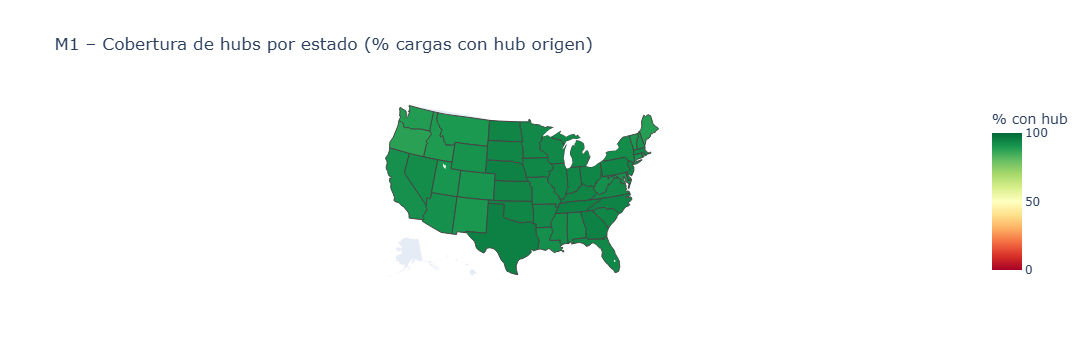

In [9]:
fig_cob = px.choropleth(
    cobertura_estado,
    locations='StateOrigin',
    locationmode='USA-states',
    color='pct_cobertura',
    scope='usa',
    color_continuous_scale='RdYlGn',
    range_color=[0, 100],
    title='M1 – Cobertura de hubs por estado (% cargas con hub origen)',
    labels={'pct_cobertura': '% con hub', 'StateOrigin': 'Estado'}
)
fig_cob.show()

## 5. Ratio inbound/outbound por estado

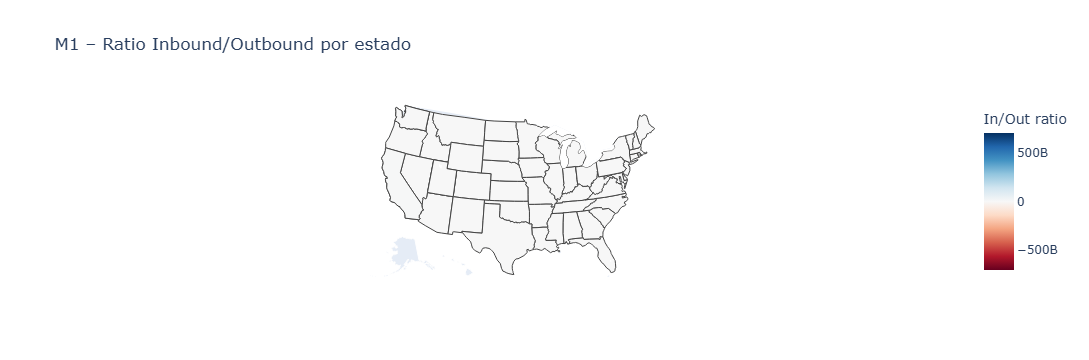

In [10]:
outbound = df.groupby('StateOrigin')['ID'].count().rename('outbound')
inbound  = df.groupby('StateDestination')['ID'].count().rename('inbound')
io_ratio = pd.concat([outbound, inbound], axis=1).fillna(0)
io_ratio['ratio'] = io_ratio['inbound'] / (io_ratio['outbound'] + 1e-9)
io_ratio = io_ratio.reset_index().rename(columns={'index': 'state'})

fig_io = px.choropleth(
    io_ratio,
    locations='state',
    locationmode='USA-states',
    color='ratio',
    scope='usa',
    color_continuous_scale='RdBu',
    color_continuous_midpoint=1.0,
    title='M1 – Ratio Inbound/Outbound por estado',
    labels={'ratio': 'In/Out ratio', 'state': 'Estado'}
)
fig_io.show()

In [11]:
sample = df[['LatOrigin', 'LngOrigin']].dropna().sample(min(20_000, len(df)), random_state=42)
m_heat = folium.Map(
    location=[38.5, -96], zoom_start=4,
    tiles='https://tiles.stadiamaps.com/tiles/alidade_smooth_dark/{z}/{x}/{y}{r}.png',
    attr='© Stadia Maps © OpenMapTiles © OpenStreetMap contributors'
)
HeatMap(sample.values.tolist(), radius=8, blur=10, min_opacity=0.3).add_to(m_heat)
m_heat.save('map_m1_heatmap.html')
print('✓ Mapa guardado: map_m1_heatmap.html')

✓ Mapa guardado: map_m1_heatmap.html


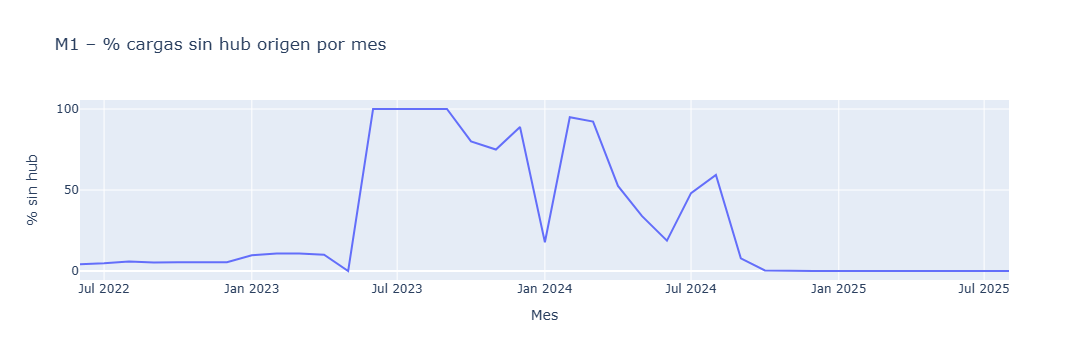

In [12]:
if 'Posted' in df.columns:
    df['Posted'] = pd.to_datetime(df['Posted'], errors='coerce')
    df['mes'] = df['Posted'].dt.to_period('M').astype(str)
    evolucion = (
        df.groupby('mes')
        .agg(total=('ID', 'count'), sin_hub=('tiene_hub_origen', lambda x: (~x).sum()))
        .assign(pct_sin_hub=lambda x: 100 * x['sin_hub'] / x['total'])
        .reset_index()
    )
    fig_ev = px.line(
        evolucion, x='mes', y='pct_sin_hub',
        title='M1 – % cargas sin hub origen por mes',
        labels={'pct_sin_hub': '% sin hub', 'mes': 'Mes'}
    )
    fig_ev.show()

## 8. Análisis por región

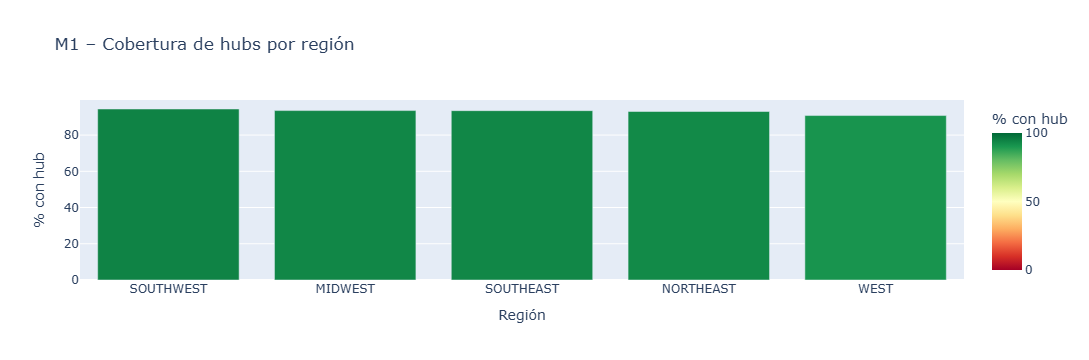

In [13]:
df['region_origen'] = df['StateOrigin'].map(region5)
region_stats = (
    df.groupby('region_origen')
    .agg(
        total=('ID', 'count'),
        con_hub=('tiene_hub_origen', 'sum')
    )
    .assign(pct_cobertura=lambda x: 100 * x['con_hub'] / x['total'])
    .reset_index()
    .sort_values('pct_cobertura', ascending=False)
)

fig_reg = px.bar(
    region_stats, x='region_origen', y='pct_cobertura',
    color='pct_cobertura', color_continuous_scale='RdYlGn',
    range_color=[0, 100],
    title='M1 – Cobertura de hubs por región',
    labels={'pct_cobertura': '% con hub', 'region_origen': 'Región'}
)
fig_reg.show()

## 9. Rate per mile por hub (top 20)

## 10. Deadhead por hub (distancia carga → hub asignado)

In [14]:
hub_coords = hubs[['new_name', 'lat', 'lng']].rename(
    columns={'lat': 'hub_lat', 'lng': 'hub_lng'}
)
df_dh = (
    df[df['HubOrigin'].notna() & df['LatOrigin'].notna()]
    .merge(hub_coords, left_on='HubOrigin', right_on='new_name', how='left')
)

# Haversine vectorizado: una sola operación sobre todas las filas
df_dh['deadhead_mi'] = haversine_vec(
    df_dh['LatOrigin'].values, df_dh['LngOrigin'].values,
    df_dh['hub_lat'].values,   df_dh['hub_lng'].values
)

print(f'Deadhead promedio global: {df_dh["deadhead_mi"].mean():.1f} millas')
print(f'Deadhead mediano global:  {df_dh["deadhead_mi"].median():.1f} millas')
print(f'% cargas con deadhead <= 50mi: {100*(df_dh["deadhead_mi"] <= 50).mean():.1f}%')

fig_dh = px.histogram(
    df_dh[df_dh['deadhead_mi'] <= 300],
    x='deadhead_mi', nbins=60,
    title='M1 – Distribución de deadhead (distancia carga → hub asignado)',
    labels={'deadhead_mi': 'Deadhead (millas)', 'count': 'N cargas'}
)
fig_dh.add_vline(x=50,  line_dash='dash', annotation_text='50 mi')
fig_dh.add_vline(x=100, line_dash='dash', annotation_text='100 mi')
fig_dh.show()

Deadhead promedio global: 33.7 millas
Deadhead mediano global:  32.3 millas
% cargas con deadhead <= 50mi: 80.4%


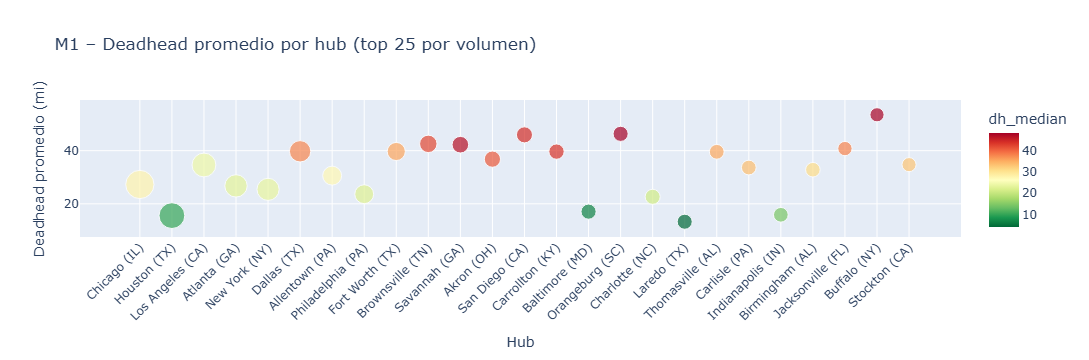

In [15]:
# Deadhead promedio por hub (top 20 por volumen)
dh_hub = (
    df_dh.groupby('HubOrigin')['deadhead_mi']
    .agg(['mean', 'median', 'count'])
    .reset_index()
    .rename(columns={'mean': 'dh_mean', 'median': 'dh_median',
                     'count': 'n_cargas', 'HubOrigin': 'hub'})
    .sort_values('n_cargas', ascending=False)
    .head(25)
)

fig_dh_hub = px.scatter(
    dh_hub, x='hub', y='dh_mean',
    size='n_cargas', color='dh_median',
    color_continuous_scale='RdYlGn_r',
    title='M1 – Deadhead promedio por hub (top 25 por volumen)',
    labels={'dh_mean': 'Deadhead promedio (mi)', 'hub': 'Hub', 'n_cargas': 'N cargas'}
)
fig_dh_hub.update_layout(xaxis_tickangle=-45)
fig_dh_hub.show()

In [16]:
# df_dh ya no se usa — liberar memoria
del df_dh
gc.collect()

479

## 11. Conectividad entre hubs (flujos origen → destino)

In [17]:
# Flujo de cargas entre pares de hubs (origen → destino)
flujos = (
    df[df['HubOrigin'].notna() & df['HubDestination'].notna()]
    .groupby(['HubOrigin', 'HubDestination'])['ID']
    .count()
    .reset_index()
    .rename(columns={'ID': 'cargas', 'HubOrigin': 'origen', 'HubDestination': 'destino'})
    .sort_values('cargas', ascending=False)
)

print(f'Pares de hubs con flujo: {len(flujos):,}')
flujos.head(15)

Pares de hubs con flujo: 55,534


,origen,destino,cargas
28271,Los Angeles (CA),Stockton (CA),143082
21299,Houston (TX),Dallas (TX),115303
21318,Houston (TX),Fort Worth (TX),95079
1274,Allentown (PA),New York (NY),89229
11491,Dallas (TX),Houston (TX),87183
8856,Chicago (IL),Chicago (IL),82629
34955,New York (NY),New York (NY),81924
8829,Chicago (IL),Ann Arbor (MI),75878
28167,Los Angeles (CA),Glendale (AZ),70720
16872,Fort Worth (TX),Houston (TX),70242


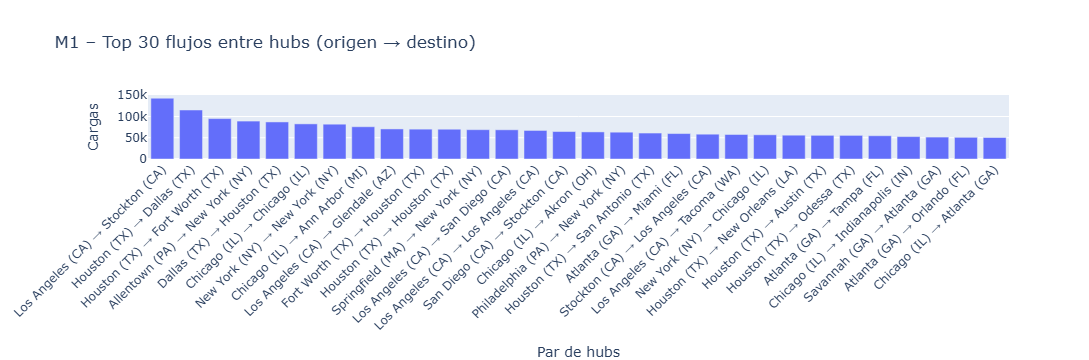

In [18]:
# Top 30 flujos: bar chart
top_flujos = flujos.head(30).copy()
top_flujos['par'] = top_flujos['origen'] + ' → ' + top_flujos['destino']

fig_flujo = px.bar(
    top_flujos, x='par', y='cargas',
    title='M1 – Top 30 flujos entre hubs (origen → destino)',
    labels={'cargas': 'Cargas', 'par': 'Par de hubs'}
)
fig_flujo.update_layout(xaxis_tickangle=-45)
fig_flujo.show()

In [19]:
hub_latlng = hubs.set_index('new_name')[['lat', 'lng']].to_dict('index')
m_conn = folium.Map(
    location=[38.5, -96], zoom_start=4,
    tiles='https://tiles.stadiamaps.com/tiles/alidade_smooth_dark/{z}/{x}/{y}{r}.png',
    attr='© Stadia Maps © OpenMapTiles © OpenStreetMap contributors'
)
max_fl = flujos['cargas'].iloc[0] if len(flujos) > 0 else 1

for _, row in flujos.head(50).iterrows():
    o, d = hub_latlng.get(row['origen']), hub_latlng.get(row['destino'])
    if o and d:
        weight = max(1, int(5 * row['cargas'] / max_fl))
        folium.PolyLine(
            [[o['lat'], o['lng']], [d['lat'], d['lng']]],
            weight=weight, color='#00aaff', opacity=0.6,
            tooltip=f"{row['origen']} → {row['destino']}: {row['cargas']:,}"
        ).add_to(m_conn)

for _, row in hubs.dropna(subset=['lat', 'lng']).iterrows():
    folium.CircleMarker(
        [row['lat'], row['lng']], radius=4,
        color='white', fill=True, fill_opacity=0.8,
        popup=row['new_name']
    ).add_to(m_conn)

m_conn.save('map_m1_conectividad.html')
print('✓ Mapa guardado: map_m1_conectividad.html')

✓ Mapa guardado: map_m1_conectividad.html


## 12. Distancia promedio de cargas por hub

Distancia promedio global de cargas: 728 millas
Distancia mediana global:            567 millas


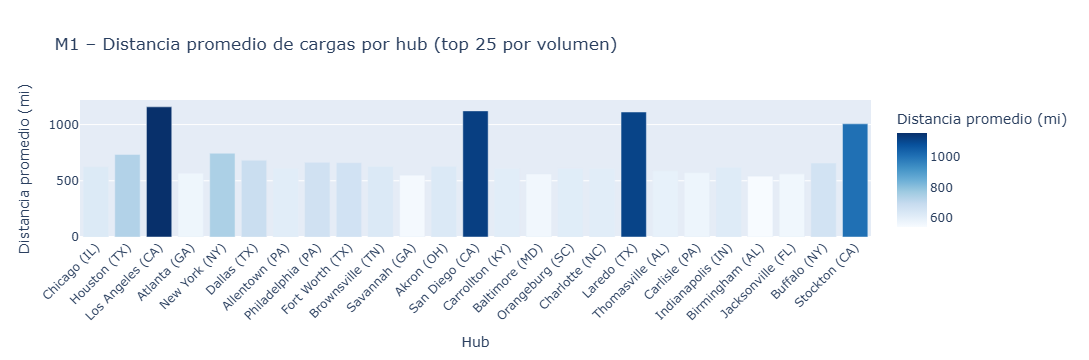

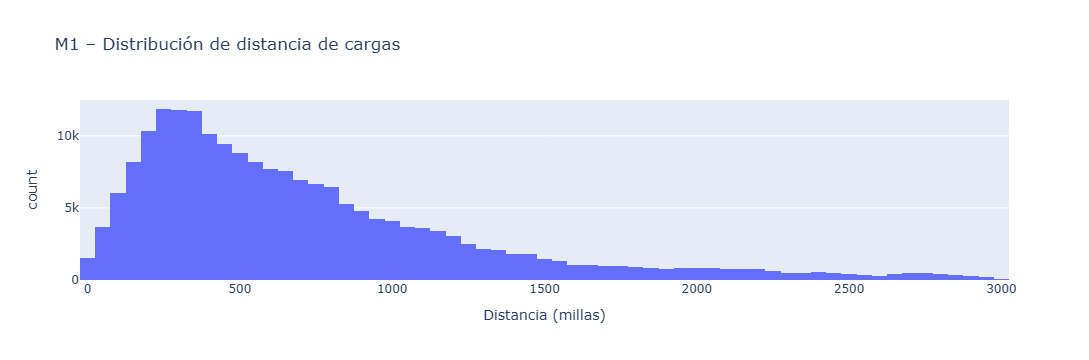

In [22]:
if 'Distance' in df.columns:
    dist_hub = (
        df[df['HubOrigin'].notna()]
        .groupby('HubOrigin')['Distance']
        .agg(['mean', 'median', 'count'])
        .reset_index()
        .rename(columns={'mean': 'dist_mean', 'median': 'dist_median',
                         'count': 'n_cargas', 'HubOrigin': 'hub'})
        .sort_values('n_cargas', ascending=False)
    )

    print(f'Distancia promedio global de cargas: {df["Distance"].mean():.0f} millas')
    print(f'Distancia mediana global:            {df["Distance"].median():.0f} millas')

    fig_dist = px.bar(
        dist_hub.head(25),
        x='hub', y='dist_mean',
        color='dist_mean', color_continuous_scale='Blues',
        title='M1 – Distancia promedio de cargas por hub (top 25 por volumen)',
        labels={'dist_mean': 'Distancia promedio (mi)', 'hub': 'Hub'}
    )
    fig_dist.update_layout(xaxis_tickangle=-45)
    fig_dist.show()

    # Histograma global — sin color por hub (plotly colorear millones de filas es lento)
    sample_dist = df[df['Distance'] < 3000]['Distance'].dropna()
    if len(sample_dist) > 200_000:
        sample_dist = sample_dist.sample(200_000, random_state=42)
    fig_dist_hist = px.histogram(
        sample_dist, x='Distance', nbins=80,
        title='M1 – Distribución de distancia de cargas',
        labels={'Distance': 'Distancia (millas)', 'count': 'N cargas'}
    )
    fig_dist_hist.show()

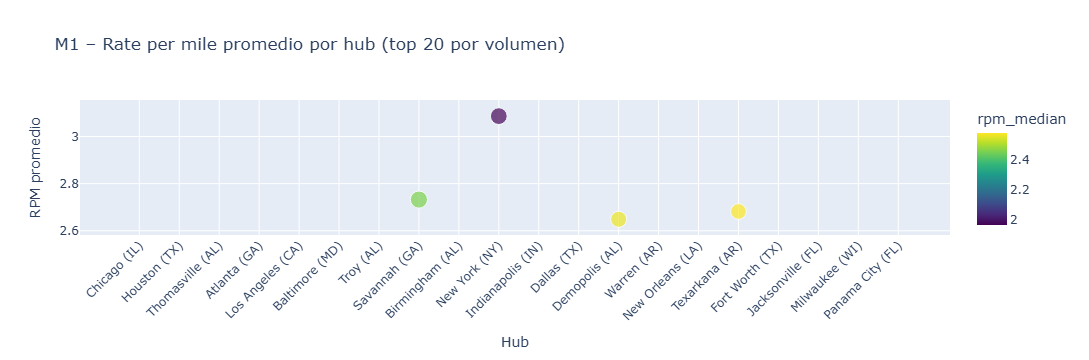

In [23]:
if 'RatePerMile' in df.columns:
    rpm_hub = (
        df[df['HubOrigin'].notna()]
        .groupby('HubOrigin')['RatePerMile']
        .agg(['mean', 'median', 'count'])
        .reset_index()
        .rename(columns={'mean': 'rpm_mean', 'median': 'rpm_median', 'count': 'n_cargas', 'HubOrigin': 'hub'})
        .sort_values('n_cargas', ascending=False)
        .head(20)
    )
    fig_rpm = px.scatter(
        rpm_hub, x='hub', y='rpm_mean',
        size='n_cargas', color='rpm_median',
        color_continuous_scale='Viridis',
        title='M1 – Rate per mile promedio por hub (top 20 por volumen)',
        labels={'rpm_mean': 'RPM promedio', 'hub': 'Hub', 'n_cargas': 'N cargas'}
    )
    fig_rpm.update_layout(xaxis_tickangle=-45)
    fig_rpm.show()